In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [20]:
transactions = pd.read_excel("../data/transactions.xlsx")

In [21]:
transactions.shape

(541909, 8)

In [22]:
transactions.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [23]:
transactions.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [24]:
transactions.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [25]:
transactions.duplicated().sum()

np.int64(5268)

In [26]:
transactions = transactions.dropna(subset=["CustomerID"])
transactions = transactions.drop_duplicates()
print("duplicates:",transactions.duplicated().sum())
print(transactions.isna().sum())

duplicates: 0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [27]:
transactions["Quantity"].describe().T

count    401604.000000
mean         12.183273
std         250.283037
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

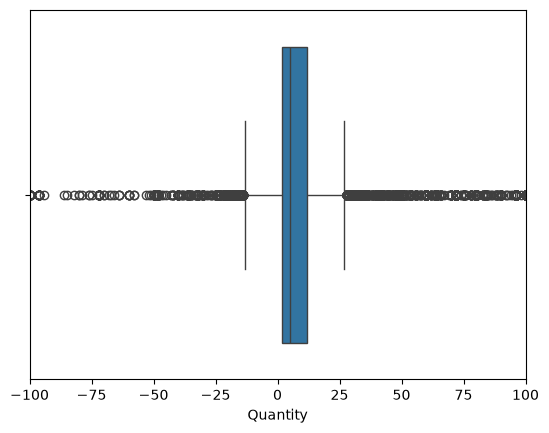

In [28]:
sns.boxplot(data=transactions, x="Quantity")
plt.xlim(-100, 100)
plt.show()


looks like there are lots of extreeme negative and positive outliers but still not sure if they are valid values or not it's bette to check their description in case 

In [29]:
transactions["UnitPrice"].describe()

count    401604.000000
mean          3.474064
std          69.764035
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max       38970.000000
Name: UnitPrice, dtype: float64

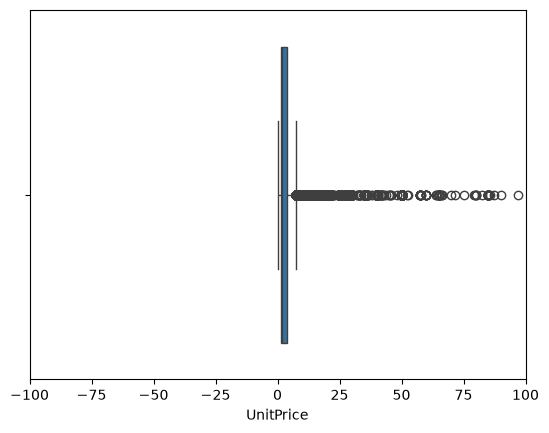

In [30]:
sns.boxplot(data=transactions, x="UnitPrice")
plt.xlim(-100, 100)
plt.show()

for unitprice looks there are only extreem positive outliers they could be of expensive products not sure yet, but this at least tell us that negative values could be valid as a way to describe returned products. but I'll clean negative value anyway let's say it's invalide value to have negative value

In [31]:
transactions = transactions[
    (transactions["Quantity"] > 0) &
    (transactions["UnitPrice"] > 0)
].copy()

(0.0, 100.0)

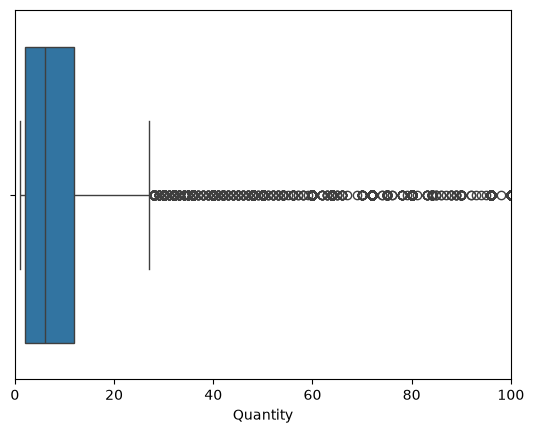

In [32]:
sns.boxplot(transactions,x="Quantity")
plt.xlim(0,100)

## Construction of rfm

In [ ]:
refDate = transactions["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = transactions.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda dates: (refDate - dates.max()).days),
    Frequency=("InvoiceNo","nunique")
).join(
    transactions.groupby("CustomerID").apply(
        lambda t: (t["UnitPrice"] * t["Quantity"]).sum())
    .rename("Monetary")
)

Recency        int64
Frequency      int64
Monetary     float64
dtype: object

In [35]:
rfm.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.0000,51.00,142.0000,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


In [36]:
rfm.to_csv("../data/rfm.csv")